In [1]:
!pip install -q timm==0.9.12 albumentations==1.3.1 segmentation-models-pytorch

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 58.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.7/125.7 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.6 MB/s eta 0:00:00


In [2]:
import pandas as pd

# Path to the dataset's official color dictionary
dict_path = "/kaggle/input/datasets/carlolepelaars/camvid/CamVid/class_dict.csv"

try:
    df = pd.read_csv(dict_path)
    # Search for anything named Pavement or Sidewalk
    target_classes = df[df['name'].str.contains('Pavement|Sidewalk', case=False)]
    print("Found these matching classes in the dataset's dictionary:")
    print(target_classes)
except FileNotFoundError:
    print(f"Could not find class_dict.csv at {dict_path}. Check the file path on the left menu!")

Found these matching classes in the dataset's dictionary:
        name  r  g    b
19  Sidewalk  0  0  192


In [3]:
import os

# Run this FIRST to discover the actual folder structure
dataset_root = "/kaggle/input"
for root, dirs, files in os.walk(dataset_root):
    depth = root.replace(dataset_root, "").count(os.sep)
    if depth > 4: continue   # don't go too deep
    indent = "  " * depth
    print(f"{indent}{os.path.basename(root)}/")
    if depth >= 3:
        # show a sample of files at leaf level
        for f in files[:3]:
            print(f"{indent}  {f}")
        if len(files) > 3:
            print(f"{indent}  ... ({len(files)} total files)")

input/
  datasets/
    carlolepelaars/
      camvid/
        CamVid/
          class_dict.csv


In [4]:
import os, random, math, warnings, json
from pathlib import Path
from typing import List, Tuple, Dict, Optional
 
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from PIL import Image
from tqdm.auto import tqdm
 
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.cuda.amp import GradScaler, autocast
 
import albumentations as A
from albumentations.pytorch import ToTensorV2
import timm
 
warnings.filterwarnings("ignore")
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

torch.backends.cudnn.benchmark = True
 
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {DEVICE}")
print(f"timm   : {timm.__version__}")

Device : cuda
timm   : 0.9.12


In [5]:
# ── CELL 3: Config & Constants ────────────────────────────────────────────────
def _resolve_backbone() -> str:
    for name in ["mit_b2", "convnext_base"]:
        if timm.list_models(name):
            print(f"  Backbone: {name}")
            return name
    raise RuntimeError("No supported backbone found.")

# CamVid 11 classes (street-scene, perfect for the paper)
CAMVID_CLASSES = [
    "Sky", "Building", "Pole", "Road", "Pavement",
    "Tree", "SignSymbol", "Fence", "Car", "Pedestrian", "Bicyclist",
]
NUM_CLASSES = 11

# RGB palette for each class (used for decode_segmap & mask conversion)
CAMVID_PALETTE = np.array([
    [128, 128, 128],   # Sky
    [128,   0,   0],   # Building
    [192, 192, 128],   # Pole
    [128,  64, 128],   # Road
    [  0,   0, 192],   # Pavement
    [128, 128,   0],   # Tree
    [192, 128, 128],   # SignSymbol
    [ 64,  64, 128],   # Fence
    [ 64,   0, 128],   # Car
    [ 64,  64,   0],   # Pedestrian
    [  0, 128, 192],   # Bicyclist
], dtype=np.uint8)

# Build RGB→class_index lookup (fast)
_RGB2IDX = {}
for _i, _rgb in enumerate(CAMVID_PALETTE):
    _RGB2IDX[tuple(_rgb)] = _i

IGNORE_INDEX = 255   # unlabelled pixels

CFG = dict(
    # ── Paths (CamVid on Kaggle) ──
    train_img  = "/kaggle/input/datasets/carlolepelaars/camvid/CamVid/train",
    train_mask = "/kaggle/input/datasets/carlolepelaars/camvid/CamVid/train_labels",
    val_img    = "/kaggle/input/datasets/carlolepelaars/camvid/CamVid/val",
    val_mask   = "/kaggle/input/datasets/carlolepelaars/camvid/CamVid/val_labels",
    # ── Model ──
    backbone   = _resolve_backbone(),
    img_size   = 512,
    num_classes= NUM_CLASSES,
    dropout_p  = 0.1,
    # ── Training ──
    epochs     = 60,
    batch_size = 8,
    val_batch  = 4,
    lr         = 6e-5,
    wd         = 0.01,
    accum_steps= 2,
    # ── Loss weights ──
    w_lovasz   = 0.45,
    w_focal    = 0.40,
    w_bnd_bce  = 0.10,
    w_aux      = 0.05,
    focal_gamma= 2.0,
    bnd_weight = 3.0,
    # ── Inference ──
    mc_samples = 20,
    tta        = True,
    # ── Misc ──
    save_path  = "best_model.pth",
    ignore_idx = IGNORE_INDEX,
    num_workers= 2,     # CamVid is small, 2 workers is fine
    seed       = 42,
)

# Class frequency weights for CamVid (inverse frequency, clipped)
CAMVID_FREQ = np.array([
    0.203, 0.151, 0.015, 0.168, 0.045,
    0.118, 0.012, 0.020, 0.116, 0.022, 0.018,
])
CLASS_WEIGHTS = np.clip(1.0 / (CAMVID_FREQ + 1e-3), 0.5, 10.0)
CLASS_WEIGHTS = torch.tensor(
    CLASS_WEIGHTS / CLASS_WEIGHTS.mean(), dtype=torch.float32
).to(DEVICE)

BDD_CLASSES  = CAMVID_CLASSES   # keep variable name used in metrics/plots
BDD_PALETTE  = CAMVID_PALETTE

  Backbone: convnext_base


In [6]:
# ── CELL 4: Dataset ───────────────────────────────────────────────────────────
def rgb_mask_to_index(rgb_mask: np.ndarray) -> np.ndarray:
    """
    Converts an RGB mask (H, W, 3) to a class index mask (H, W) using 
    nearest-neighbor distance to avoid exact-match color corruption.
    """
    # Reshape image to (H*W, 3)
    flat_mask = rgb_mask.reshape(-1, 3).astype(np.float32)
    palette   = CAMVID_PALETTE.astype(np.float32)
    
    # Calculate Euclidean distance from every pixel to every palette color
    # Resulting shape: (H*W, 11)
    dists = np.linalg.norm(flat_mask[:, None, :] - palette[None, :, :], axis=2)
    
    # Find the index of the closest color for each pixel
    idx_flat = np.argmin(dists, axis=1)
    
    # Optional safety net: If a pixel is a completely random color, ignore it
    min_dists = np.min(dists, axis=1)
    idx_flat[min_dists > 30.0] = IGNORE_INDEX 
    
    # Reshape back to (H, W)
    return idx_flat.reshape(rgb_mask.shape[:2]).astype(np.int64)


class CamVidDataset(Dataset):
    """
    CamVid dataset

    Folder layout (carlolepelaars/camvid on Kaggle):
        train/          *.png images
        train_labels/   *_L.png RGB colour masks
        val/
        val_labels/
    """
    def __init__(self, img_dir: str, mask_dir: str,
                 transform=None, boundary_width: int = 3):
        self.img_dir  = Path(img_dir)
        self.mask_dir = Path(mask_dir)
        self.transform= transform
        self.bw       = boundary_width

        # CamVid images are .png; labels end with _L.png
        self.ids = sorted([
            p.stem for p in self.img_dir.glob("*.png")
            if "_L" not in p.stem          # exclude any label files
        ])
        # Fallback: try jpg
        if not self.ids:
            self.ids = sorted([p.stem for p in self.img_dir.glob("*.jpg")])

        print(f"  {len(self.ids)} samples in {img_dir}")

    def __len__(self): return len(self.ids)

    def __getitem__(self, idx):
        stem = self.ids[idx]

        # ── Load image ──
        for ext in [".png", ".jpg"]:
            p = self.img_dir / f"{stem}{ext}"
            if p.exists(): break
        img = np.array(Image.open(p).convert("RGB"))

        # ── Load mask (RGB → index) ──
        # CamVid label files are named  <stem>_L.png
        for label_name in [f"{stem}_L.png", f"{stem}.png"]:
            mp = self.mask_dir / label_name
            if mp.exists(): break
        rgb_mask = np.array(Image.open(mp).convert("RGB"))
        mask     = rgb_mask_to_index(rgb_mask)         # (H, W) uint8

        # ── Augment ──
        if self.transform:
            aug  = self.transform(image=img, mask=mask)
            img, mask = aug["image"], aug["mask"]

        mask_np  = mask.numpy() if torch.is_tensor(mask) else mask
        boundary = self._make_boundary(mask_np)

        return (img,
                torch.tensor(mask_np, dtype=torch.long),
                torch.tensor(boundary, dtype=torch.float32))

    def _make_boundary(self, mask: np.ndarray) -> np.ndarray:
        kernel   = np.ones((self.bw, self.bw), dtype=np.uint8)
        boundary = np.zeros_like(mask, dtype=np.uint8)
        for c in range(NUM_CLASSES):
            cm  = (mask == c).astype(np.uint8)
            dil = cv2.dilate(cm, kernel, iterations=1)
            boundary |= (dil - cm)
        boundary[mask == CFG["ignore_idx"]] = 0
        return boundary.astype(np.float32)

def get_transforms(cfg):
    S = cfg["img_size"]
    train_tf = A.Compose([
        A.RandomResizedCrop(S, S, scale=(0.4, 2.0), ratio=(0.75, 1.33)),
        A.HorizontalFlip(p=0.5),
        A.ColorJitter(brightness=0.3, contrast=0.3,
                      saturation=0.3, hue=0.1, p=0.8),
        A.GaussianBlur(blur_limit=(3,7), p=0.3),
        A.RandomFog(fog_coef_lower=0.05, fog_coef_upper=0.25, p=0.2),
        A.RandomRain(slant_lower=-10, slant_upper=10,
                     drop_length=15, p=0.15),
        A.CoarseDropout(max_holes=8, max_height=S//16,
                        max_width=S//16, p=0.1),
        A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)),
        ToTensorV2(),
    ])
    val_tf = A.Compose([
        A.Resize(S, S),
        A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)),
        ToTensorV2(),
    ])
    return train_tf, val_tf

In [7]:
class GatedBoundaryFusion(nn.Module):
    """
    Learned gate: boundary features modulate main decoder features.
      gate  = σ(Conv([seg; bnd]))
      out   = seg + gate ⊙ Conv([seg; bnd])
    """
    def __init__(self, channels: int):
        super().__init__()
        self.gate = nn.Sequential(
            nn.Conv2d(channels*2, channels, 1, bias=False),
            nn.BatchNorm2d(channels),
            nn.Sigmoid(),
        )
        self.fuse = nn.Sequential(
            nn.Conv2d(channels*2, channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True),
        )
 
    def forward(self, seg: torch.Tensor, bnd: torch.Tensor) -> torch.Tensor:
        cat  = torch.cat([seg, bnd], dim=1)
        gate = self.gate(cat)
        feat = self.fuse(cat)
        return seg + gate * feat
 
 
class BoundaryBranch(nn.Module):
    """Lightweight CNN for explicit edge prediction on finest-scale features."""
    def __init__(self, in_ch: int, mid_ch: int = 64):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(in_ch, mid_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(mid_ch), nn.ReLU(inplace=True),
            nn.Conv2d(mid_ch, mid_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(mid_ch), nn.ReLU(inplace=True),
        )
        self.logit = nn.Conv2d(mid_ch, 1, 1)    # binary boundary logit
        self.feat  = nn.Conv2d(mid_ch, mid_ch, 1)  # features for gating
 
    def forward(self, x):
        h = self.body(x)
        return self.logit(h), self.feat(h)
 
 
class AllMLPDecoder(nn.Module):
    """
    SegFormer All-MLP decoder: project all 4 scales to dim D,
    upsample to stride-4 resolution, fuse, return (B,D,H/4,W/4).
    """
    def __init__(self, enc_channels=(64,128,320,512), dim=256):
        super().__init__()
        self.dim  = dim
        self.proj = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(c, dim, 1, bias=False),
                nn.BatchNorm2d(dim),
                nn.ReLU(inplace=True),
            ) for c in enc_channels
        ])
        self.fuse = nn.Sequential(
            nn.Conv2d(dim * len(enc_channels), dim, 1, bias=False),
            nn.BatchNorm2d(dim),
            nn.ReLU(inplace=True),
        )
 
    def forward(self, feats: List[torch.Tensor]) -> torch.Tensor:
        target = feats[0].shape[2:]   # H/4, W/4
        outs = []
        for f, p in zip(feats, self.proj):
            x = p(f)
            if x.shape[2:] != target:
                x = F.interpolate(x, size=target, mode="bilinear",
                                  align_corners=False)
            outs.append(x)
        return self.fuse(torch.cat(outs, dim=1))
 
 
class AuxHead(nn.Module):
    """Deep supervision auxiliary head on stage-3 features (improvement #1)."""
    def __init__(self, in_ch: int = 320, num_classes: int = NUM_CLASSES):
        super().__init__()
        self.head = nn.Sequential(
            nn.Conv2d(in_ch, 256, 3, padding=1, bias=False),
            nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.Dropout2d(0.1),
            nn.Conv2d(256, num_classes, 1),
        )
 
    def forward(self, x, size):
        x = self.head(x)
        return F.interpolate(x, size=size, mode="bilinear", align_corners=False)
 
 
class BoundaryUncertainSeg(nn.Module):
    """
    Full model pipeline:
      timm MiT-B2 encoder (4 stage features)
      → BoundaryBranch (on C1)
      → AllMLPDecoder (all 4 stages)
      → GatedBoundaryFusion
      → MC-Dropout head
      → seg logits + boundary logit [+ aux logit during training]
    """
    def __init__(self, cfg: dict):
        super().__init__()
        self.cfg = cfg
        nc = cfg["num_classes"]
 
        # ── Encoder (fixed: timm features_only) ──
        self.encoder = timm.create_model(
            cfg["backbone"], pretrained=True,
            features_only=True, out_indices=(0,1,2,3),
        )
        enc_ch = self.encoder.feature_info.channels()   # [64,128,320,512]
 
        # ── Boundary branch on finest features ──
        self.bnd_branch = BoundaryBranch(enc_ch[0], mid_ch=64)
        self.bnd_proj   = nn.Conv2d(64, 256, 1)
 
        # ── Main decoder ──
        self.decoder = AllMLPDecoder(enc_ch, dim=256)
 
        # ── Gated fusion ──
        self.gated_fusion = GatedBoundaryFusion(256)
 
        # ── Auxiliary deep supervision head ──
        self.aux_head = AuxHead(enc_ch[2], nc)
 
        # ── Main segmentation head with MC dropout ──
        self.dropout  = nn.Dropout2d(cfg["dropout_p"])
        self.seg_head = nn.Conv2d(256, nc, 1)
 
    def forward(self, x: torch.Tensor):
        H, W = x.shape[2:]
        feats = self.encoder(x)              # list of 4 feature maps
 
        # Boundary branch
        bnd_logit, bnd_feat = self.bnd_branch(feats[0])
 
        # Auxiliary head (on stage-3 features, only used in training)
        aux_logit = self.aux_head(feats[2], (H, W)) if self.training else None
 
        # Main decoder
        dec = self.decoder(feats)            # (B, 256, H/4, W/4)
 
        # Gated boundary fusion
        bnd_feat_up = F.interpolate(
            self.bnd_proj(bnd_feat), size=dec.shape[2:],
            mode="bilinear", align_corners=False,
        )
        dec = self.gated_fusion(dec, bnd_feat_up)
 
        # Head
        dec = self.dropout(dec)
        seg = self.seg_head(dec)
        seg = F.interpolate(seg, size=(H,W), mode="bilinear", align_corners=False)
        bnd_logit = F.interpolate(bnd_logit, size=(H,W),
                                  mode="bilinear", align_corners=False)
        return seg, bnd_logit, aux_logit
 
    @torch.no_grad()
    def predict_with_uncertainty(self, x: torch.Tensor,
                                 n: int = 20) -> Tuple[torch.Tensor, torch.Tensor]:
        """
        MC Dropout inference: keep dropout active for n passes.
        Returns (mean_prob [B,C,H,W], uncertainty [B,H,W])
        """
        self.train()   # activate Dropout2d
        probs = []
        for _ in range(n):
            seg, _, _ = self.forward(x)
            probs.append(F.softmax(seg, dim=1))
        probs = torch.stack(probs)           # (n, B, C, H, W)
        mean  = probs.mean(0)                # (B, C, H, W)
        eps   = 1e-8
        ent   = -(mean * (mean+eps).log()).sum(1)   # (B,H,W) entropy
        unc   = ent / math.log(self.cfg["num_classes"])  # normalize to [0,1]
        self.eval()
        return mean, unc
 
    @torch.no_grad()
    def predict_tta(self, x: torch.Tensor) -> torch.Tensor:
        """
        Test-Time Augmentation: average original + H-flip + multi-scale.
        Returns averaged softmax probabilities (B,C,H,W).
        """
        self.eval()
        scales = [0.75, 1.0, 1.25]
        H, W   = x.shape[2:]
        probs  = torch.zeros(x.shape[0], NUM_CLASSES, H, W, device=x.device)
        count  = 0
        for s in scales:
            nh, nw = int(H*s), int(W*s)
            xi = F.interpolate(x, (nh,nw), mode="bilinear", align_corners=False)
            for flip in [False, True]:
                xf = xi.flip(-1) if flip else xi
                seg, _, _ = self.forward(xf)
                if flip: seg = seg.flip(-1)
                seg = F.interpolate(seg, (H,W), mode="bilinear", align_corners=False)
                probs += F.softmax(seg, dim=1)
                count += 1
        return probs / count
        

In [8]:
def _lovász_grad(gt_sorted: torch.Tensor) -> torch.Tensor:
    n   = len(gt_sorted)
    gts = gt_sorted.sum()
    inter = gts - gt_sorted.float().cumsum(0)
    union = gts + (1 - gt_sorted).float().cumsum(0)
    iou   = 1.0 - inter / union
    if n > 1:
        iou[1:] = iou[1:] - iou[:-1]
    return iou
 
def lovász_softmax_per_image(probs: torch.Tensor, labels: torch.Tensor,
                              ignore: int = 255) -> torch.Tensor:
    """probs: (C, N), labels: (N,)"""
    valid = labels != ignore
    probs, labels = probs[:, valid], labels[valid]
    C = probs.shape[0]
    losses = []
    for c in labels.unique():
        c = c.item()
        fg = (labels == c).float()
        if fg.sum() == 0: continue
        err = (fg - probs[c]).abs()
        err_s, idx = err.sort(descending=True)
        fg_s = fg[idx]
        losses.append((err_s * _lovász_grad(fg_s)).sum())
    return torch.stack(losses).mean() if losses else probs.sum() * 0.0
 
def lovász_softmax_loss(logits: torch.Tensor, labels: torch.Tensor,
                         ignore: int = 255) -> torch.Tensor:
    B, C, H, W = logits.shape
    probs = F.softmax(logits, dim=1)
    loss  = 0.0
    for b in range(B):
        p = probs[b].view(C, -1)
        l = labels[b].view(-1)
        loss += lovász_softmax_per_image(p, l, ignore)
    return loss / B
 
 
# ── 6b. Online Hard Example Mining (OHEM) Focal Loss (improvement #2) ────────
class OHEMFocalLoss(nn.Module):
    """
    Focal loss with Online Hard Example Mining.
    Keeps only the top-K hardest pixels per batch (ohem_ratio of valid pixels).
    Boundary pixels get extra weight.
    """
    def __init__(self, gamma: float = 2.0, bnd_weight: float = 3.0,
                 ohem_ratio: float = 0.7, ignore_index: int = 255,
                 class_weights: Optional[torch.Tensor] = None):
        super().__init__()
        self.gamma       = gamma
        self.bnd_weight  = bnd_weight
        self.ohem_ratio  = ohem_ratio
        self.ignore_idx  = ignore_index
        self.class_weights = class_weights
 
    def forward(self, logits: torch.Tensor, labels: torch.Tensor,
                boundary: torch.Tensor) -> torch.Tensor:
        B, C, H, W = logits.shape
        # Per-pixel cross entropy (with class weights)
        ce = F.cross_entropy(
            logits, labels,
            weight=self.class_weights,
            ignore_index=self.ignore_idx,
            reduction="none",
        )                                    # (B, H, W)
        pt     = torch.exp(-ce)
        focal  = ((1 - pt) ** self.gamma) * ce
 
        # Boundary up-weighting
        w = 1.0 + (self.bnd_weight - 1.0) * boundary
        focal = focal * w
 
        # OHEM: keep hardest pixels
        valid  = (labels != self.ignore_idx).view(B, -1)  # (B, H*W)
        focal  = focal.view(B, -1)
        losses = []
        for b in range(B):
            v_idx = valid[b].nonzero(as_tuple=True)[0]
            if v_idx.numel() == 0: continue
            pix   = focal[b][v_idx]
            k     = max(1, int(self.ohem_ratio * v_idx.numel()))
            hard, _ = pix.topk(k)
            losses.append(hard.mean())
        return torch.stack(losses).mean() if losses else focal.sum() * 0.0
 
 
# ── 6c. Combined Loss ─────────────────────────────────────────────────────────
class HybridLoss(nn.Module):
    def __init__(self, cfg: dict, class_weights: torch.Tensor):
        super().__init__()
        self.w_lovasz  = cfg["w_lovasz"]
        self.w_focal   = cfg["w_focal"]
        self.w_bnd_bce = cfg["w_bnd_bce"]
        self.w_aux     = cfg["w_aux"]
        self.ignore    = cfg["ignore_idx"]
        self.focal     = OHEMFocalLoss(
            gamma       = cfg["focal_gamma"],
            bnd_weight  = cfg["bnd_weight"],
            ohem_ratio  = 0.7,
            ignore_index= cfg["ignore_idx"],
            class_weights = class_weights,
        )
        self.bce = nn.BCEWithLogitsLoss()
 
    def forward(self, seg_logit, bnd_logit, aux_logit,
                labels, boundary) -> Tuple[torch.Tensor, dict]:
        # 1. Lovász (IoU surrogate)
        l_lov  = lovász_softmax_loss(seg_logit, labels, self.ignore)
        # 2. OHEM Boundary-Weighted Focal
        l_foc  = self.focal(seg_logit, labels, boundary)
        # 3. Boundary BCE
        l_bnd  = self.bce(bnd_logit.squeeze(1), boundary)
        # 4. Auxiliary deep supervision
        l_aux  = F.cross_entropy(aux_logit, labels, ignore_index=self.ignore) \
                 if aux_logit is not None else seg_logit.sum() * 0.0
 
        total  = (self.w_lovasz * l_lov
                  + self.w_focal  * l_foc
                  + self.w_bnd_bce* l_bnd
                  + self.w_aux    * l_aux)
        parts  = dict(lovasz=l_lov.item(), focal=l_foc.item(),
                      bnd=l_bnd.item(),   aux=l_aux.item(),
                      total=total.item())
        return total, parts

In [9]:
class SegMetrics:
    def __init__(self, num_classes=NUM_CLASSES, ignore=255):
        self.nc  = num_classes
        self.ign = ignore
        self.reset()
 
    def reset(self):
        self.conf = np.zeros((self.nc, self.nc), dtype=np.int64)
 
    def update(self, pred: np.ndarray, label: np.ndarray):
        valid = label != self.ign
        p, l  = pred[valid].astype(np.int64), label[valid].astype(np.int64)
        p = np.clip(p, 0, self.nc-1)
        l = np.clip(l, 0, self.nc-1)
        self.conf += np.bincount(self.nc*l + p, minlength=self.nc**2) \
                       .reshape(self.nc, self.nc)
 
    def miou(self) -> float:
        iou = []
        for c in range(self.nc):
            tp = self.conf[c,c]
            fp = self.conf[:,c].sum() - tp
            fn = self.conf[c,:].sum() - tp
            d  = tp + fp + fn
            if d > 0: iou.append(tp/d)
        return float(np.mean(iou)) if iou else 0.0
 
    def pixel_acc(self) -> float:
        return float(np.diag(self.conf).sum() / (self.conf.sum() + 1e-8))
 
    def per_class_iou(self) -> dict:
        iou = {}
        for c in range(self.nc):
            tp = self.conf[c,c]
            d  = self.conf[:,c].sum() + self.conf[c,:].sum() - tp
            iou[BDD_CLASSES[c]] = float(tp/d) if d > 0 else float("nan")
        return iou

In [10]:
class PolyLR(torch.optim.lr_scheduler._LRScheduler):
    """Standard poly LR decay for segmentation: lr = base_lr*(1-iter/max)^power"""
    def __init__(self, optimizer, max_iters: int, power: float = 0.9,
                 warmup_iters: int = 0, last_epoch: int = -1):
        self.max_iters   = max_iters
        self.power       = power
        self.warmup_iters= warmup_iters
        super().__init__(optimizer, last_epoch)
 
    def get_lr(self):
        it = self.last_epoch
        if it < self.warmup_iters:
            factor = (it + 1) / (self.warmup_iters + 1)
        else:
            factor = (1 - (it - self.warmup_iters) /
                      (self.max_iters - self.warmup_iters + 1e-8)) ** self.power
        return [base_lr * factor for base_lr in self.base_lrs]

In [11]:
class Trainer:
    def __init__(self, model, train_loader, val_loader, cfg):
        self.model  = model.to(DEVICE)
        self.tl     = train_loader
        self.vl     = val_loader
        self.cfg    = cfg
 
        self.criterion = HybridLoss(cfg, CLASS_WEIGHTS)
 
        # Separate LRs: backbone gets 10× smaller lr (standard practice)
        encoder_params = list(model.encoder.parameters())
        other_params   = [p for p in model.parameters()
                          if not any(p is ep for ep in encoder_params)]
        self.optimizer = torch.optim.AdamW([
            {"params": encoder_params, "lr": cfg["lr"] * 0.1},
            {"params": other_params,   "lr": cfg["lr"]},
        ], weight_decay=cfg["wd"])
 
        total_iters = cfg["epochs"] * math.ceil(len(train_loader) / cfg["accum_steps"])
        self.scheduler = PolyLR(
            self.optimizer, max_iters=total_iters,
            power=0.9, warmup_iters=int(0.05 * total_iters),
        )
        self.scaler  = GradScaler()
        self.history = dict(train_loss=[], val_miou=[], val_acc=[])
        self.best_miou = 0.0
 
    # ── train one epoch ──────────────────────────────────────────────────────
    def train_epoch(self, epoch: int) -> float:
        self.model.train()
        running = dict(total=0., lovasz=0., focal=0., bnd=0., aux=0.)
        pbar = tqdm(self.tl, desc=f"Ep{epoch+1:02d}/Train", leave=False)
        self.optimizer.zero_grad()
 
        for step, (imgs, masks, bnds) in enumerate(pbar):
            imgs  = imgs.to(DEVICE, non_blocking=True)
            masks = masks.to(DEVICE, non_blocking=True)
            bnds  = bnds.to(DEVICE, non_blocking=True)
 
            with autocast():
                seg, bnd, aux = self.model(imgs)
                loss, parts   = self.criterion(seg, bnd, aux, masks, bnds)
                loss = loss / self.cfg["accum_steps"]
 
            self.scaler.scale(loss).backward()
 
            if (step + 1) % self.cfg["accum_steps"] == 0:
                self.scaler.unscale_(self.optimizer)
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)
                self.scaler.step(self.optimizer)
                self.scaler.update()
                self.optimizer.zero_grad()
                self.scheduler.step()
 
            for k in running:
                running[k] += parts.get(k, 0.)
            pbar.set_postfix(loss=f"{parts['total']:.4f}")
 
        n = len(self.tl)
        avg = running["total"] / n
        self.history["train_loss"].append(avg)
        lr = self.optimizer.param_groups[1]["lr"]
        print(f"  [Train] loss={avg:.4f}  "
              f"lov={running['lovasz']/n:.3f}  "
              f"foc={running['focal']/n:.3f}  "
              f"bnd={running['bnd']/n:.3f}  "
              f"aux={running['aux']/n:.3f}  lr={lr:.2e}")
        return avg
 
    # ── validate ─────────────────────────────────────────────────────────────
    @torch.no_grad()
    def validate(self, epoch: int) -> float:
        self.model.eval()
        metrics = SegMetrics()
        pbar = tqdm(self.vl, desc=f"Ep{epoch+1:02d}/Val ", leave=False)
 
        for imgs, masks, _ in pbar:
            imgs = imgs.to(DEVICE, non_blocking=True)
            # Use TTA if configured
            if self.cfg["tta"]:
                probs = self.model.predict_tta(imgs)
                preds = probs.argmax(1).cpu().numpy()
            else:
                with autocast():
                    seg, _, _ = self.model(imgs)
                preds = seg.argmax(1).cpu().numpy()
 
            for p, m in zip(preds, masks.numpy()):
                metrics.update(p, m)
 
        miou = metrics.miou()
        acc  = metrics.pixel_acc()
        self.history["val_miou"].append(miou)
        self.history["val_acc"].append(acc)
        print(f"  [Val]   mIoU={miou:.4f}  PixAcc={acc:.4f}")
 
        if miou > self.best_miou:
            self.best_miou = miou
            
            torch.save({"epoch": epoch, "state_dict": self.model.state_dict(),
                        "miou": miou, "history": self.history},
                       self.cfg["save_path"])
            print(f"  ★ Best mIoU {miou:.4f} — saved.")
        return miou
 
    # ── main loop ────────────────────────────────────────────────────────────
    def fit(self):
        print(f"\n{'='*60}")
        print(f" BoundaryUncertainSeg — training {self.cfg['epochs']} epochs")
        print(f" Device: {DEVICE}  |  Backbone: {self.cfg['backbone']}")
        print(f"{'='*60}")
        for ep in range(self.cfg["epochs"]):
            self.train_epoch(ep)
            self.validate(ep)
        print(f"\n Best mIoU: {self.best_miou:.4f}")
        return self.history

In [12]:
def decode_segmap(lbl: np.ndarray) -> np.ndarray:
    out = np.zeros((*lbl.shape, 3), dtype=np.uint8)
    for c, rgb in enumerate(BDD_PALETTE):
        out[lbl == c] = rgb
    return out
 
INV_MEAN = np.array([0.485,0.456,0.406])
INV_STD  = np.array([0.229,0.224,0.225])
 
def denorm(t: torch.Tensor) -> np.ndarray:
    img = t.permute(1,2,0).numpy()
    return np.clip(img * INV_STD + INV_MEAN, 0, 1)
 
 
def visualize_predictions(model, dataset, n=4, save="preds.png"):
    random.seed(42)
    idxs = random.sample(range(len(dataset)), n)
    fig, axes = plt.subplots(n, 4, figsize=(22, 5.5*n),
                              facecolor="#0d1117")
    titles = ["Original Image", "Ground Truth", "Prediction", "Uncertainty Map"]
    for col, t in enumerate(titles):
        axes[0, col].set_title(t, color="white", fontsize=13, pad=8,
                                fontweight="bold")
 
    for row, idx in enumerate(idxs):
        img_t, mask, _ = dataset[idx]
        x = img_t.unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            mean_p, unc = model.predict_with_uncertainty(
                x, n=model.cfg["mc_samples"])
        pred = mean_p.argmax(1).squeeze().cpu().numpy()
        unc  = unc.squeeze().cpu().numpy()
        img  = denorm(img_t)
        gt   = decode_segmap(mask.numpy())
 
        for col, (data, kw) in enumerate([
            (img,              dict(vmin=None, vmax=None, cmap=None)),
            (gt,               dict(vmin=None, vmax=None, cmap=None)),
            (decode_segmap(pred), dict(vmin=None, vmax=None, cmap=None)),
            (unc,              dict(vmin=0, vmax=1, cmap="plasma")),
        ]):
            ax = axes[row, col]
            ax.set_facecolor("#0d1117"); ax.axis("off")
            im = ax.imshow(data, **{k:v for k,v in kw.items() if v is not None}
                           if kw["cmap"] else {}) if kw["cmap"] is None \
                 else ax.imshow(data, cmap=kw["cmap"],
                                vmin=kw["vmin"], vmax=kw["vmax"])
            if col == 3:
                cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.01)
                cb.ax.tick_params(colors="white", labelsize=8)
 
    plt.tight_layout(pad=0.3)
    plt.savefig(save, dpi=150, bbox_inches="tight",
                facecolor=fig.get_facecolor())
    plt.show()
    print(f"Saved → {save}")
 
 
def plot_training_curves(history: dict, save="curves.png"):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14,5), facecolor="#0d1117")
    for ax in (a1, a2):
        ax.set_facecolor("#161b22")
        for sp in ax.spines.values(): sp.set_edgecolor("#30363d")
        ax.tick_params(colors="white"); ax.xaxis.label.set_color("white")
        ax.yaxis.label.set_color("white"); ax.title.set_color("white")
 
    epochs = range(1, len(history["train_loss"])+1)
    a1.plot(epochs, history["train_loss"], color="#58a6ff", lw=2)
    a1.set_title("Training Loss"); a1.set_xlabel("Epoch"); a1.set_ylabel("Loss")
 
    a2.plot(epochs, history["val_miou"], color="#3fb950", lw=2, label="mIoU")
    a2.plot(epochs, history["val_acc"],  color="#f78166", lw=2, label="PixAcc")
    a2.set_title("Validation Metrics"); a2.set_xlabel("Epoch")
    a2.legend(facecolor="#161b22", labelcolor="white")
 
    plt.tight_layout()
    plt.savefig(save, dpi=150, bbox_inches="tight",
                facecolor=fig.get_facecolor())
    plt.show()
 
 
def plot_per_class_iou(metrics: SegMetrics, save="class_iou.png"):
    iou_d = metrics.per_class_iou()
    vals  = [v if not math.isnan(v) else 0 for v in iou_d.values()]
    cols  = [f"#{r:02x}{g:02x}{b:02x}" for r,g,b in BDD_PALETTE]
    fig, ax = plt.subplots(figsize=(16,5), facecolor="#0d1117")
    ax.set_facecolor("#161b22")
    for sp in ax.spines.values(): sp.set_edgecolor("#30363d")
    bars = ax.bar(list(iou_d.keys()), vals, color=cols, edgecolor="#30363d")
    ax.set_ylim(0, 1); ax.set_ylabel("IoU", color="white")
    ax.set_title("Per-Class IoU", color="white", fontsize=13)
    ax.tick_params(axis="x", rotation=45, colors="white")
    ax.tick_params(axis="y", colors="white")
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, v+0.01,
                f"{v:.2f}", ha="center", fontsize=7, color="white")
    plt.tight_layout()
    plt.savefig(save, dpi=150, bbox_inches="tight",
                facecolor=fig.get_facecolor())
    plt.show()
 
 
def plot_uncertainty_vs_error(model, val_loader, n_batches=8, save="unc_dist.png"):
    """Novel plot: uncertainty distribution for correct vs incorrect pixels."""
    model.train()
    correct_u, wrong_u = [], []
    with torch.no_grad():
        for i, (imgs, masks, _) in enumerate(tqdm(val_loader, desc="UncEval")):
            if i >= n_batches: break
            imgs = imgs.to(DEVICE)
            mean_p, unc = model.predict_with_uncertainty(imgs, n=10)
            preds = mean_p.argmax(1).cpu()
            unc   = unc.cpu()
            for b in range(imgs.shape[0]):
                valid = masks[b] != CFG["ignore_idx"]
                ok    = (preds[b] == masks[b]) & valid
                bad   = (preds[b] != masks[b]) & valid
                correct_u.extend(unc[b][ok].numpy().tolist())
                wrong_u.extend(unc[b][bad].numpy().tolist())
    model.eval()
 
    fig, ax = plt.subplots(figsize=(10,5), facecolor="#0d1117")
    ax.set_facecolor("#161b22")
    ax.hist(correct_u[:20000], bins=60, alpha=0.65, color="#3fb950",
            label="Correct pixels", density=True)
    ax.hist(wrong_u[:20000],   bins=60, alpha=0.65, color="#f78166",
            label="Wrong pixels",   density=True)
    ax.set_xlabel("Uncertainty (normalised entropy)", color="white")
    ax.set_ylabel("Density", color="white")
    ax.set_title("MC Dropout Uncertainty: Correct vs Wrong Predictions",
                 color="white", fontsize=12)
    ax.legend(facecolor="#161b22", labelcolor="white")
    ax.tick_params(colors="white")
    for sp in ax.spines.values(): sp.set_edgecolor("#30363d")
    plt.tight_layout()
    plt.savefig(save, dpi=150, bbox_inches="tight",
                facecolor=fig.get_facecolor())
    plt.show()


Loading datasets...
  369 samples in /kaggle/input/datasets/carlolepelaars/camvid/CamVid/train
  100 samples in /kaggle/input/datasets/carlolepelaars/camvid/CamVid/val

Building model...


model.safetensors:   0%|          | 0.00/354M [00:00<?, ?B/s]

  Trainable params: 90.95M
  Encoder channels: [128, 256, 512, 1024]

 BoundaryUncertainSeg — training 60 epochs
 Device: cuda  |  Backbone: convnext_base


Ep01/Train:   0%|          | 0/46 [00:00<?, ?it/s]

  [Train] loss=1.3393  lov=0.890  foc=1.872  bnd=0.647  aux=2.509  lr=2.06e-05


...

  [Train] loss=0.1946  lov=0.268  foc=0.103  bnd=0.246  aux=0.161  lr=5.92e-15


Ep60/Val :   0%|          | 0/25 [00:00<?, ?it/s]

  [Val]   mIoU=0.8019  PixAcc=0.9568

 Best mIoU: 0.8032

Final evaluation...


Final eval:   0%|          | 0/25 [00:00<?, ?it/s]


 Final mIoU (TTA): 0.8032
 Pixel Acc  (TTA): 0.9573


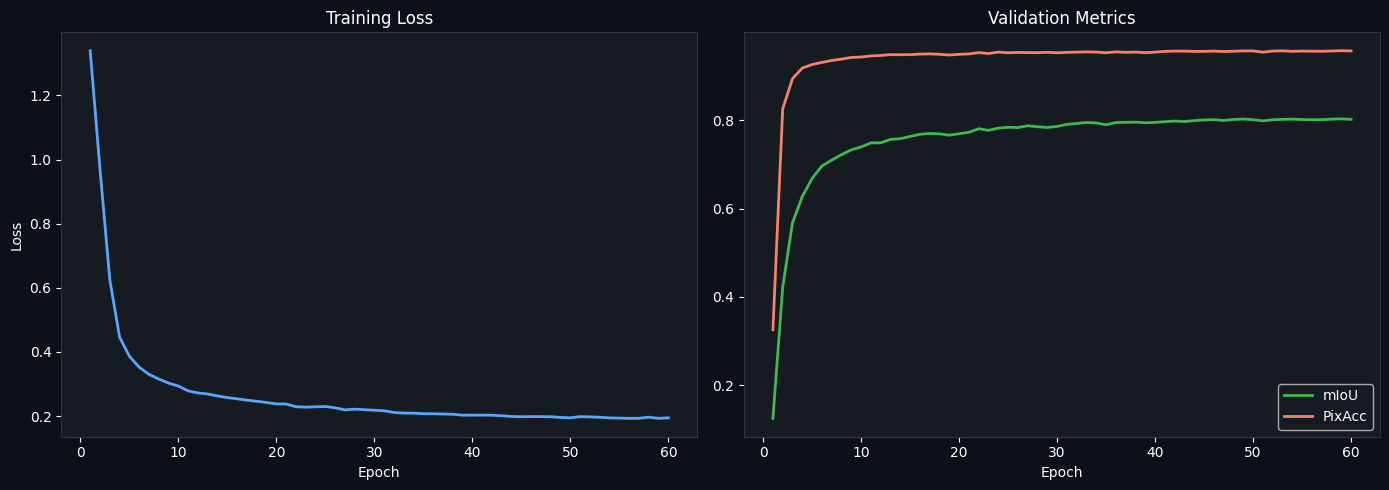

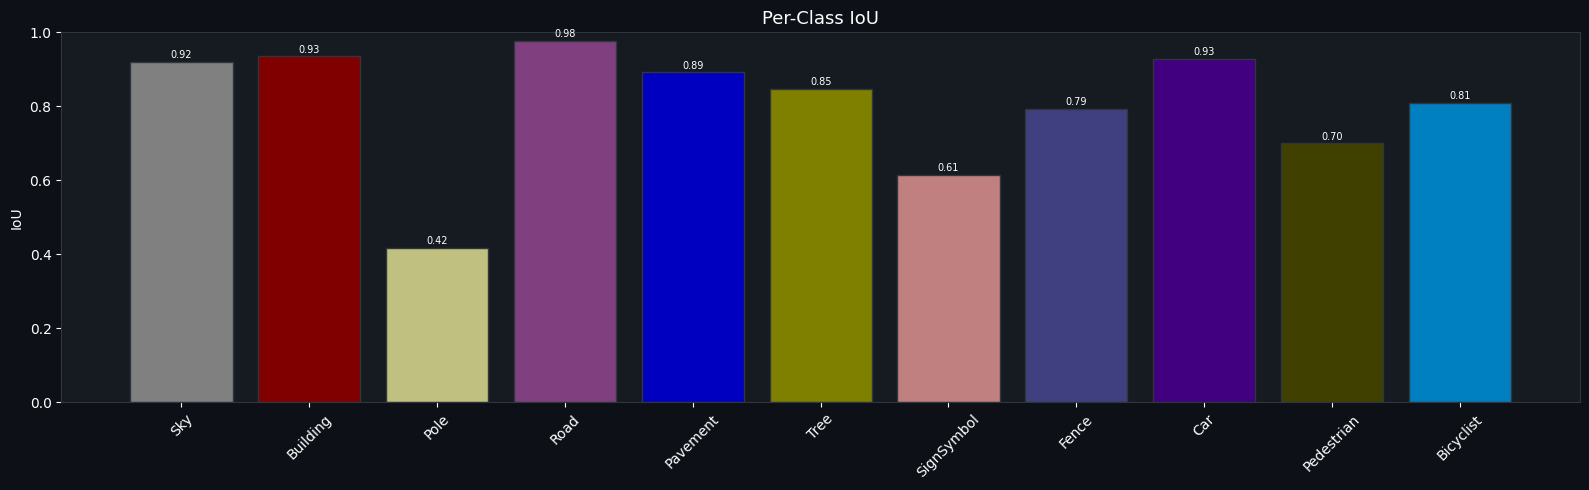

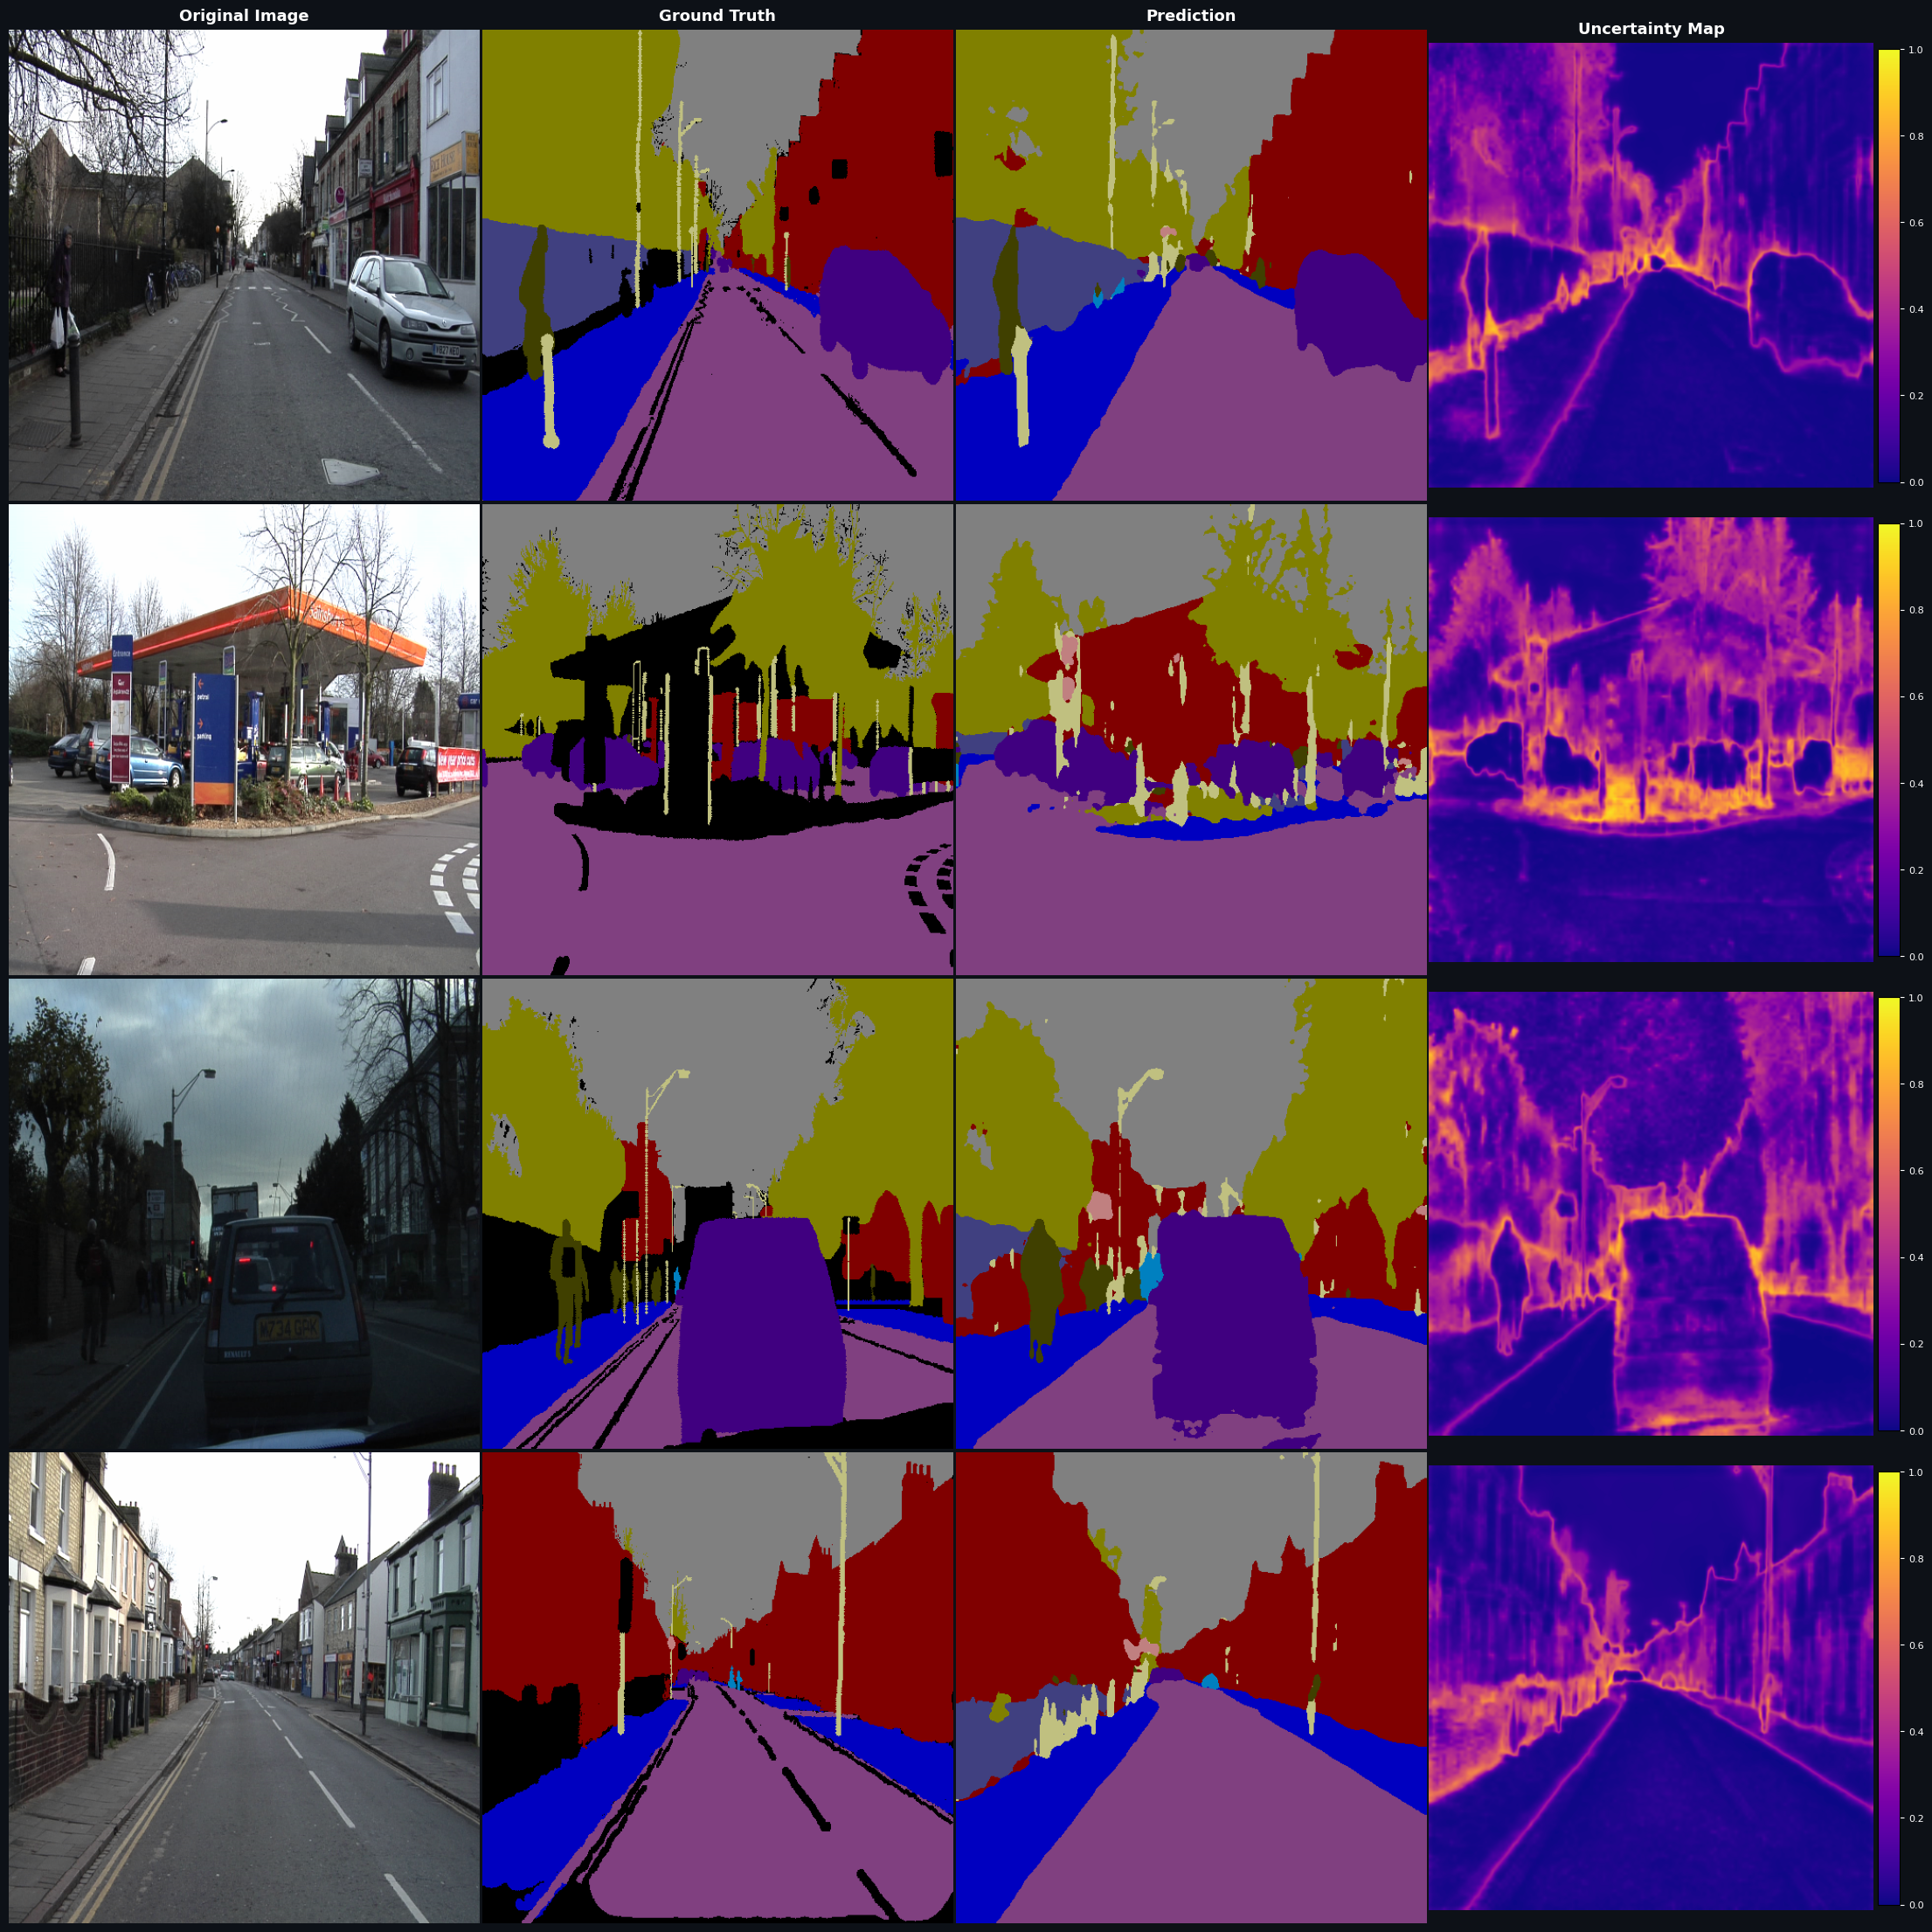

Saved → preds.png


UncEval:   0%|          | 0/25 [00:00<?, ?it/s]

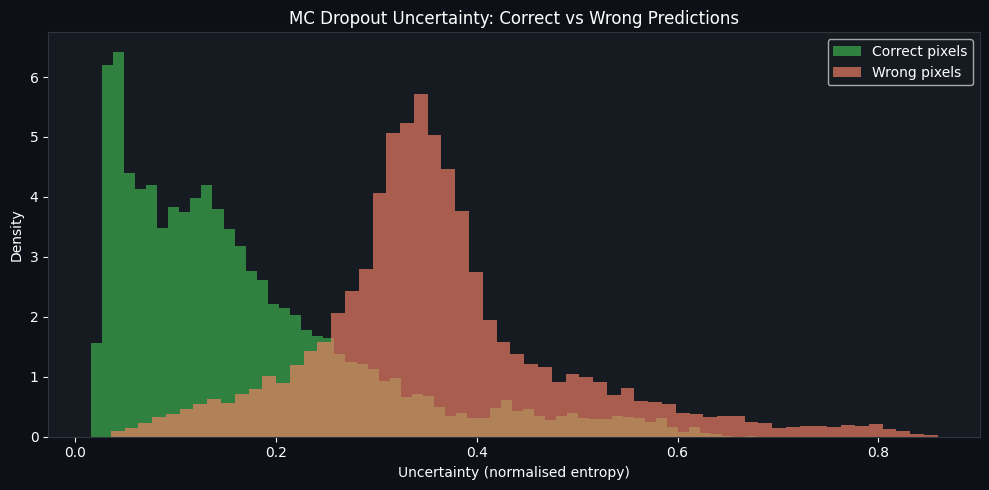

In [13]:
def main():
    train_tf, val_tf = get_transforms(CFG)
 
    print("\nLoading datasets...")
    train_ds = CamVidDataset(CFG["train_img"], CFG["train_mask"], train_tf)
    val_ds   = CamVidDataset(CFG["val_img"],   CFG["val_mask"],   val_tf)
 
    train_loader = DataLoader(train_ds, batch_size=CFG["batch_size"],
                              shuffle=True, num_workers=CFG["num_workers"],
                              pin_memory=True, drop_last=True,persistent_workers=True)
    val_loader   = DataLoader(val_ds, batch_size=CFG["val_batch"],
                              shuffle=False, num_workers=CFG["num_workers"],
                              pin_memory=True,persistent_workers=True)
 
    print("\nBuilding model...")
    model  = BoundaryUncertainSeg(CFG)
    n_para = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"  Trainable params: {n_para/1e6:.2f}M")
    print(f"  Encoder channels: {model.encoder.feature_info.channels()}")
 
    trainer = Trainer(model, train_loader, val_loader, CFG)
    history = trainer.fit()
 
    # ── Load best and evaluate ──────────────────────────────────────────────
    ckpt = torch.load(CFG["save_path"])
    model.load_state_dict(ckpt["state_dict"])
    model.eval()
 
    print("\nFinal evaluation...")
    final_metrics = SegMetrics()
    with torch.no_grad():
        for imgs, masks, _ in tqdm(val_loader, desc="Final eval"):
            probs = model.predict_tta(imgs.to(DEVICE))
            preds = probs.argmax(1).cpu().numpy()
            for p, m in zip(preds, masks.numpy()):
                final_metrics.update(p, m)
 
    print(f"\n Final mIoU (TTA): {final_metrics.miou():.4f}")
    print(f" Pixel Acc  (TTA): {final_metrics.pixel_acc():.4f}")
 
    # ── Plots ────────────────────────────────────────────────────────────────
    plot_training_curves(history)
    plot_per_class_iou(final_metrics)
    visualize_predictions(model, val_ds, n=4)
    plot_uncertainty_vs_error(model, val_loader)
 
 
if __name__ == "__main__":
    main()